# metrics.ipynb — вычисление метрик bbox-предсказаний MiniCPM

## Что делает этот ноутбук

Принимает на вход сырые CSV-файлы с результатами bbox-оценки модели (из `results/`) и вычисляет метрики качества локализации объектов.

---

## Входные данные

6 CSV-файлов — по 2 части (`part0`, `part1`) для каждого из трёх подмножеств датасета `FirstMetricsData`:

| CSV-файл | Описание |
|---|---|
| `humans_frequency_part0/1` | Топ-100 видео с людьми (по частоте упоминания) |
| `human_object_part0/1` | Топ-100 видео категории человек + объект |
| `human_animal_object_part0/1` | Топ-100 видео категории человек + животное + объект |

Каждая строка CSV = один кадр одного видео с одним промтом. Содержит:
- GT bbox: `x_min_gt`, `x_max_gt`, `y_min_gt`, `y_max_gt`
- Predicted bbox в пикселях: `x_min_pred_px`, `x_max_pred_px`, `y_min_pred_px`, `y_max_pred_px`
- Флаг успеха парсинга ответа модели: `success`

---

## Вычисляемые метрики

| Метрика | Описание |
|---|---|
| **IoU** | Intersection over Union предсказанного и GT bbox |
| **GIoU** | Generalized IoU — штрафует за большое расстояние между боксами |
| **mIoU** | Среднее IoU по всем валидным кадрам (считается глобально, по выражениям и по видео) |
| **acc@50 / acc@75** | Доля кадров с IoU ≥ 0.50 / 0.75 |
| **IoU-TG** | IoU Temporal Gradient — среднее абсолютное изменение IoU между соседними кадрами (стабильность предсказаний во времени) |
| **success_rate** | Доля кадров, где модель вернула корректный bbox |

Кадры с GT bbox = `[0,0,0,0]` считаются невалидными и исключаются из агрегированных метрик.

---

## Выходные данные

Для каждого CSV создаётся папка `results/metrics/<name>/` с тремя файлами:

- **`per_frame.csv`** — метрики IoU/GIoU на каждый кадр
- **`per_expression.csv`** — агрегация по (video, expr_id): mIoU, GIoU, acc@50/75, IoU-TG
- **`per_video.csv`** — агрегация по видео: те же метрики + кол-во выражений

В конце ноутбука — сводная таблица по всем 6 CSV с глобальными summary-статистиками.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

RESULTS_DIR = Path("/home/jovyan/shares/SR006.nfs2/vashina/datasets/MeViS/results")
METRICS_DIR = RESULTS_DIR / "metrics"

ALL_CSVS = [
    "humans_frequency_part0",
    "humans_frequency_part1",
    "human_object_part0",
    "human_object_part1",
    "human_animal_object_part0",
    "human_animal_object_part1",
]

In [2]:
def _bbox_metrics(row):
    """
    Compute IoU and GIoU for a single row.
    Returns (nan, nan) if GT is empty; (0.0, -1.0) if model failed.
    """
    gt_empty = (
        row["x_min_gt"] == 0 and row["x_max_gt"] == 0
        and row["y_min_gt"] == 0 and row["y_max_gt"] == 0
    )
    if gt_empty:
        return np.nan, np.nan

    # When success=False pred bbox is [0,0,0,0] — still compute properly
    x1g, x2g = row["x_min_gt"],      row["x_max_gt"]
    y1g, y2g = row["y_min_gt"],      row["y_max_gt"]
    x1p, x2p = row["x_min_pred_px"], row["x_max_pred_px"]
    y1p, y2p = row["y_min_pred_px"], row["y_max_pred_px"]

    # Intersection
    xi1, yi1 = max(x1g, x1p), max(y1g, y1p)
    xi2, yi2 = min(x2g, x2p), min(y2g, y2p)
    inter = max(0, xi2 - xi1) * max(0, yi2 - yi1)

    gt_area   = (x2g - x1g) * (y2g - y1g)
    pred_area = (x2p - x1p) * (y2p - y1p)
    union = gt_area + pred_area - inter

    iou = inter / union if union > 0 else 0.0

    # Enclosing box for GIoU
    cx1, cy1 = min(x1g, x1p), min(y1g, y1p)
    cx2, cy2 = max(x2g, x2p), max(y2g, y2p)
    c_area = (cx2 - cx1) * (cy2 - cy1)

    giou = iou - (c_area - union) / c_area if c_area > 0 else iou

    return iou, giou


def _iou_tg(group: pd.DataFrame) -> float:
    """
    IoU Temporal Gradient for one (video_name, expr_id) group.
    Mean absolute frame-to-frame IoU change (valid frames only, sorted by n_frame).
    """
    iou_seq = (
        group[group["gt_is_valid"]]
        .sort_values("n_frame")["iou"]
        .dropna()
    )
    if len(iou_seq) < 2:
        return np.nan
    return iou_seq.diff().abs().mean()


def process_csv(name: str) -> dict:
    """
    Load raw CSV, compute per-frame metrics (IoU, GIoU) and aggregate
    per-expression and per-video. Saves three CSV files to metrics/<name>/.
    Returns a dict with global summary stats.
    """
    csv_path = RESULTS_DIR / f"{name}.csv"
    out_dir  = METRICS_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"Loading {csv_path.name} ...")
    df = pd.read_csv(csv_path)
    print(f"  Rows: {len(df):,}")

    # ------------------------------------------------------------------ #
    # per_frame — IoU + GIoU
    # ------------------------------------------------------------------ #
    metrics = df.apply(lambda r: _bbox_metrics(r), axis=1, result_type="expand")
    df["iou"]  = metrics[0]
    df["giou"] = metrics[1]
    df["gt_is_valid"] = ~(
        (df["x_min_gt"] == 0) & (df["x_max_gt"] == 0)
        & (df["y_min_gt"] == 0) & (df["y_max_gt"] == 0)
    )

    per_frame_cols = [
        "video_name", "expr_id", "prompt", "n_frame", "height", "width",
        "x_min_gt", "x_max_gt", "y_min_gt", "y_max_gt",
        "x_min_pred_px", "x_max_pred_px", "y_min_pred_px", "y_max_pred_px",
        "success", "iou", "giou", "gt_is_valid",
    ]
    df_frame = df[per_frame_cols].copy()
    df_frame.to_csv(out_dir / "per_frame.csv", index=False)
    print(f"  Saved per_frame.csv  ({len(df_frame):,} rows)")

    # ------------------------------------------------------------------ #
    # per_expression — mIoU, GIoU, acc_50, acc_75, iou_tg
    # ------------------------------------------------------------------ #
    valid = df[df["gt_is_valid"]]

    # IoU-TG per (video, expr_id)
    iou_tg_map = (
        valid
        .groupby(["video_name", "expr_id"])
        .apply(_iou_tg)
        .rename("iou_tg")
        .reset_index()
    )

    def agg_expr(g):
        iou  = g["iou"]
        giou = g["giou"]
        return pd.Series({
            "prompt":          g["prompt"].iloc[0],
            "n_frames_total":  len(g),
            "n_frames_valid":  g["gt_is_valid"].sum(),
            "mIoU":            iou.mean(),
            "mean_GIoU":       giou.mean(),
            "acc_50":          (iou >= 0.50).mean(),
            "acc_75":          (iou >= 0.75).mean(),
            "success_rate":    g["success"].mean(),
        })

    df_expr = (
        valid
        .groupby(["video_name", "expr_id"], sort=False)
        .apply(agg_expr)
        .reset_index()
        .merge(iou_tg_map, on=["video_name", "expr_id"], how="left")
    )
    df_expr.to_csv(out_dir / "per_expression.csv", index=False)
    print(f"  Saved per_expression.csv  ({len(df_expr):,} rows)")

    # ------------------------------------------------------------------ #
    # per_video — mIoU, GIoU, acc_50, acc_75, iou_tg
    # ------------------------------------------------------------------ #
    def agg_video(g):
        iou  = g["iou"]
        giou = g["giou"]
        return pd.Series({
            "n_expressions":   g["expr_id"].nunique(),
            "n_frames_total":  len(g),
            "n_frames_valid":  g["gt_is_valid"].sum(),
            "mIoU":            iou.mean(),
            "mean_GIoU":       giou.mean(),
            "acc_50":          (iou >= 0.50).mean(),
            "acc_75":          (iou >= 0.75).mean(),
            "iou_tg":          _iou_tg(g),
            "success_rate":    g["success"].mean(),
        })

    df_video = (
        valid
        .groupby("video_name", sort=False)
        .apply(agg_video)
        .reset_index()
    )
    df_video.to_csv(out_dir / "per_video.csv", index=False)
    print(f"  Saved per_video.csv  ({len(df_video):,} rows)")

    # ------------------------------------------------------------------ #
    # Global summary
    # ------------------------------------------------------------------ #
    iou_valid  = valid["iou"]
    giou_valid = valid["giou"]
    summary = {
        "name":             name,
        "n_frames_total":   len(df),
        "n_frames_valid":   len(valid),
        "n_videos":         df["video_name"].nunique(),
        "n_expressions":    df.groupby(["video_name", "expr_id"]).ngroups,
        "mIoU_global":      round(iou_valid.mean(), 4),
        "mIoU_per_video":   round(df_video["mIoU"].mean(), 4),
        "mIoU_per_expr":    round(df_expr["mIoU"].mean(), 4),
        "mean_GIoU":        round(giou_valid.mean(), 4),
        "acc_50":           round((iou_valid >= 0.50).mean(), 4),
        "acc_75":           round((iou_valid >= 0.75).mean(), 4),
        "iou_tg_per_expr":  round(df_expr["iou_tg"].mean(), 4),
        "success_rate":     round(df["success"].mean(), 4),
    }
    return summary

## humans_frequency — part 0

In [3]:
summary = process_csv("humans_frequency_part0")

print("\n=== Global summary ===")
for k, v in summary.items():
    print(f"  {k:<22} {v}")

Loading humans_frequency_part0.csv ...
  Rows: 24,985
  Saved per_frame.csv  (24,985 rows)
  Saved per_expression.csv  (295 rows)
  Saved per_video.csv  (49 rows)

=== Global summary ===
  name                   humans_frequency_part0
  n_frames_total         24985
  n_frames_valid         24408
  n_videos               49
  n_expressions          295
  mIoU_global            0.586
  mIoU_per_video         0.6364
  mIoU_per_expr          0.5784
  mean_GIoU              0.4906
  acc_50                 0.6629
  acc_75                 0.4524
  iou_tg_per_expr        0.0929
  success_rate           1.0


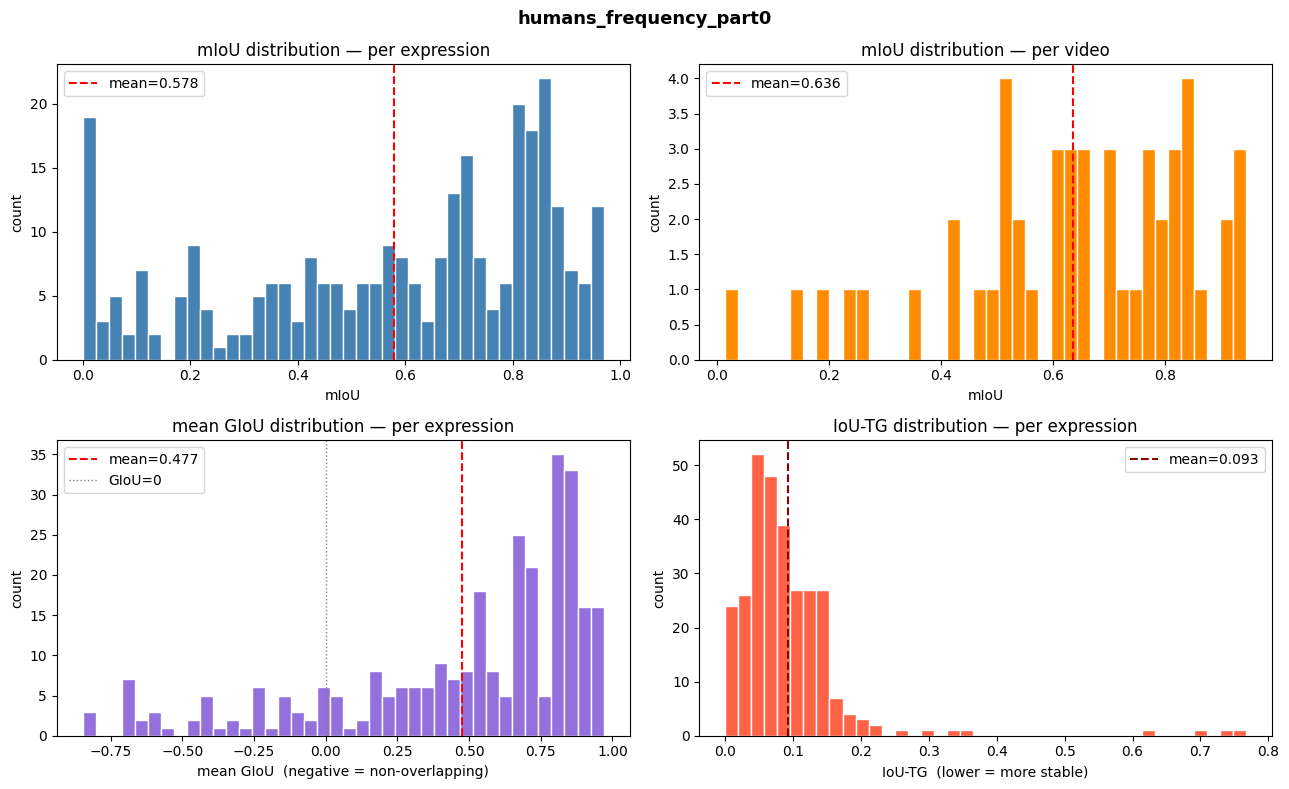


Metric                per-expr mean  per-video mean
----------------------------------------------------
  mIoU                       0.5784          0.6364
  mean_GIoU                  0.4770          0.5562
  acc_50                     0.6565          0.7308
  acc_75                     0.4405          0.5110
  iou_tg                     0.0929          0.1597
  success_rate               0.9999          0.9999


In [4]:
import matplotlib.pyplot as plt

NAME = "humans_frequency_part0"
df_expr  = pd.read_csv(METRICS_DIR / NAME / "per_expression.csv")
df_video = pd.read_csv(METRICS_DIR / NAME / "per_video.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# ── Row 1: mIoU ─────────────────────────────────────────────────────────────
for ax, data, label, color in [
    (axes[0, 0], df_expr["mIoU"],  "per expression", "steelblue"),
    (axes[0, 1], df_video["mIoU"], "per video",       "darkorange"),
]:
    ax.hist(data.dropna(), bins=40, color=color, edgecolor="white")
    ax.axvline(data.mean(), color="red", linestyle="--",
               label=f"mean={data.mean():.3f}")
    ax.set_title(f"mIoU distribution — {label}")
    ax.set_xlabel("mIoU")
    ax.set_ylabel("count")
    ax.legend()

# ── Row 2: GIoU and IoU-TG ──────────────────────────────────────────────────
giou_data = df_expr["mean_GIoU"].dropna()
axes[1, 0].hist(giou_data, bins=40, color="mediumpurple", edgecolor="white")
axes[1, 0].axvline(giou_data.mean(), color="red", linestyle="--",
                   label=f"mean={giou_data.mean():.3f}")
axes[1, 0].axvline(0, color="gray", linestyle=":", linewidth=1, label="GIoU=0")
axes[1, 0].set_title("mean GIoU distribution — per expression")
axes[1, 0].set_xlabel("mean GIoU  (negative = non-overlapping)")
axes[1, 0].set_ylabel("count")
axes[1, 0].legend()

tg_data = df_expr["iou_tg"].dropna()
axes[1, 1].hist(tg_data, bins=40, color="tomato", edgecolor="white")
axes[1, 1].axvline(tg_data.mean(), color="darkred", linestyle="--",
                   label=f"mean={tg_data.mean():.3f}")
axes[1, 1].set_title("IoU-TG distribution — per expression")
axes[1, 1].set_xlabel("IoU-TG  (lower = more stable)")
axes[1, 1].set_ylabel("count")
axes[1, 1].legend()

plt.suptitle(f"{NAME}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ── Metric summary table ─────────────────────────────────────────────────────
print(f"\n{'Metric':<20} {'per-expr mean':>14}  {'per-video mean':>14}")
print("-" * 52)
for col in ["mIoU", "mean_GIoU", "acc_50", "acc_75", "iou_tg", "success_rate"]:
    e = df_expr[col].mean() if col in df_expr else float("nan")
    v = df_video[col].mean() if col in df_video else float("nan")
    print(f"  {col:<18} {e:>14.4f}  {v:>14.4f}")

## All 6 CSVs (run after all parts are ready)

In [5]:
all_summaries = []
for name in ALL_CSVS:
    csv_path = RESULTS_DIR / f"{name}.csv"
    if not csv_path.exists():
        print(f"SKIP {name} — CSV not found")
        continue
    s = process_csv(name)
    all_summaries.append(s)
    print()

df_summary = pd.DataFrame(all_summaries)
print("\n=== Summary across all parts ===")
display(df_summary)

Loading humans_frequency_part0.csv ...
  Rows: 24,985
  Saved per_frame.csv  (24,985 rows)
  Saved per_expression.csv  (295 rows)
  Saved per_video.csv  (49 rows)

Loading humans_frequency_part1.csv ...
  Rows: 21,312
  Saved per_frame.csv  (21,312 rows)
  Saved per_expression.csv  (256 rows)
  Saved per_video.csv  (50 rows)

Loading human_object_part0.csv ...
  Rows: 44,820
  Saved per_frame.csv  (44,820 rows)
  Saved per_expression.csv  (652 rows)
  Saved per_video.csv  (42 rows)

Loading human_object_part1.csv ...
  Rows: 41,307
  Saved per_frame.csv  (41,307 rows)
  Saved per_expression.csv  (609 rows)
  Saved per_video.csv  (43 rows)

Loading human_animal_object_part0.csv ...
  Rows: 119,173
  Saved per_frame.csv  (119,173 rows)
  Saved per_expression.csv  (1,669 rows)
  Saved per_video.csv  (48 rows)

Loading human_animal_object_part1.csv ...
  Rows: 75,300
  Saved per_frame.csv  (75,300 rows)
  Saved per_expression.csv  (1,347 rows)
  Saved per_video.csv  (48 rows)


=== Summary

,name,n_frames_total,n_frames_valid,n_videos,n_expressions,mIoU_global,mIoU_per_video,mIoU_per_expr,mean_GIoU,acc_50,acc_75,iou_tg_per_expr,success_rate
0,humans_frequency_part0,24985,24408,49,295,0.5860,0.6364,0.5784,0.4906,0.6629,0.4524,0.0929,1.0000
1,humans_frequency_part1,21312,19844,50,256,0.6560,0.6717,0.6358,0.6130,0.7945,0.4801,0.0998,0.9999
2,human_object_part0,44820,37990,42,652,0.5005,0.5004,0.4855,0.3827,0.5582,0.3377,0.1221,0.9991
3,human_object_part1,41307,33522,43,609,0.4698,0.4497,0.4551,0.3375,0.5485,0.2841,0.1296,0.9998
4,human_animal_object_part0,119173,74729,48,1669,0.4799,0.4985,0.4780,0.3475,0.5431,0.3068,0.1607,0.9997
5,human_animal_object_part1,75300,61676,48,1347,0.4522,0.4868,0.4732,0.3179,0.5016,0.2540,0.1471,0.9997


Loaded 4,828 expressions from 6 file(s):
  humans_frequency_part0                     295 expressions
  humans_frequency_part1                     256 expressions
  human_object_part0                         652 expressions
  human_object_part1                         609 expressions
  human_animal_object_part0                 1669 expressions
  human_animal_object_part1                 1347 expressions


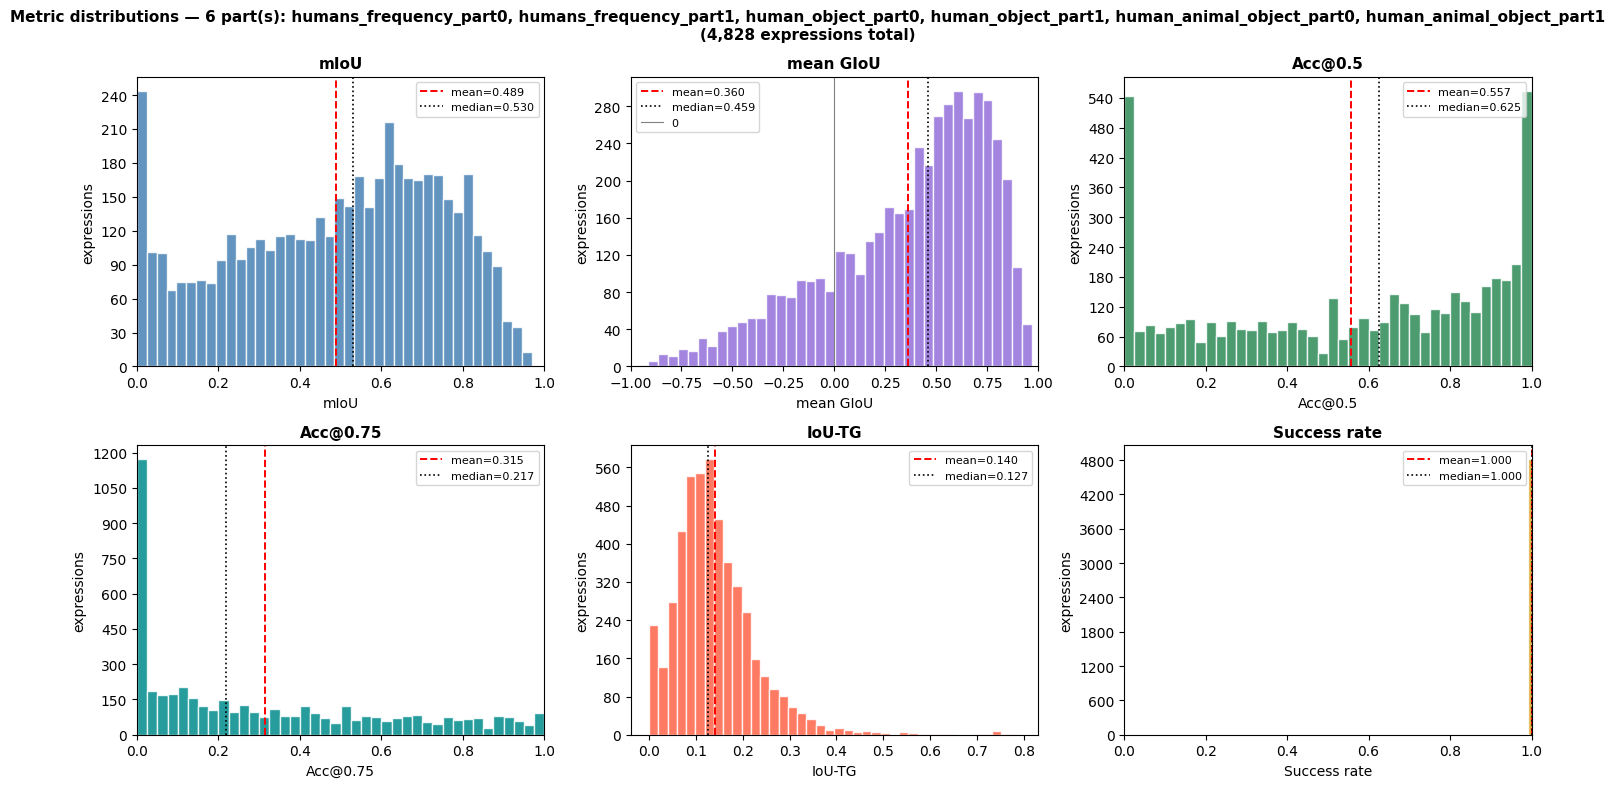


Metric             mean    median       std       min       max
------------------------------------------------------------
  mIoU           0.4893    0.5298    0.2581    0.0000    0.9690
  mean GIoU      0.3596    0.4591    0.4011   -0.9606    0.9689
  Acc@0.5        0.5571    0.6250    0.3468    0.0000    1.0000
  Acc@0.75       0.3147    0.2174    0.3065    0.0000    1.0000
  IoU-TG         0.1404    0.1267    0.0880    0.0000    0.7906
  Success rate   0.9999    1.0000    0.0057    0.6250    1.0000


In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Load all available per_expression CSVs ───────────────────────────────────
frames = []
for name in ALL_CSVS:
    path = METRICS_DIR / name / "per_expression.csv"
    if path.exists():
        df_tmp = pd.read_csv(path)
        df_tmp["source"] = name
        frames.append(df_tmp)

if not frames:
    raise RuntimeError("No per_expression.csv found — run process_csv first.")

df_all = pd.concat(frames, ignore_index=True)
print(f"Loaded {len(df_all):,} expressions from {len(frames)} file(s):")
for f in frames:
    src = f["source"].iloc[0]
    print(f"  {src:<40}  {len(f):>4} expressions")

# ── Plot ─────────────────────────────────────────────────────────────────────
METRICS = [
    ("mIoU",         "mIoU",        "steelblue",     (0, 1),   True),
    ("mean_GIoU",    "mean GIoU",   "mediumpurple",  (-1, 1),  True),
    ("acc_50",       "Acc@0.5",     "seagreen",      (0, 1),   True),
    ("acc_75",       "Acc@0.75",    "darkcyan",      (0, 1),   True),
    ("iou_tg",       "IoU-TG",      "tomato",        None,     False),
    ("success_rate", "Success rate","goldenrod",     (0, 1),   True),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (col, label, color, xlim, add_vline_zero) in zip(axes, METRICS):
    data = df_all[col].dropna()
    ax.hist(data, bins=40, color=color, edgecolor="white", alpha=0.85)

    mean_val = data.mean()
    median_val = data.median()
    ax.axvline(mean_val,   color="red",    linestyle="--", linewidth=1.4,
               label=f"mean={mean_val:.3f}")
    ax.axvline(median_val, color="black",  linestyle=":",  linewidth=1.2,
               label=f"median={median_val:.3f}")

    if add_vline_zero and col == "mean_GIoU":
        ax.axvline(0, color="gray", linestyle="-", linewidth=0.8, label="0")

    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("expressions")
    if xlim:
        ax.set_xlim(*xlim)
    ax.legend(fontsize=8)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

n_sources = len(frames)
src_label = ", ".join(f["source"].iloc[0] for f in frames)
fig.suptitle(
    f"Metric distributions — {n_sources} part(s): {src_label}\n"
    f"({len(df_all):,} expressions total)",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.show()

# ── Summary stats table ───────────────────────────────────────────────────────
print(f"\n{'Metric':<14} {'mean':>8}  {'median':>8}  {'std':>8}  {'min':>8}  {'max':>8}")
print("-" * 60)
for col, label, *_ in METRICS:
    d = df_all[col].dropna()
    print(f"  {label:<12} {d.mean():>8.4f}  {d.median():>8.4f}  "
          f"{d.std():>8.4f}  {d.min():>8.4f}  {d.max():>8.4f}")

Failed rows: 1


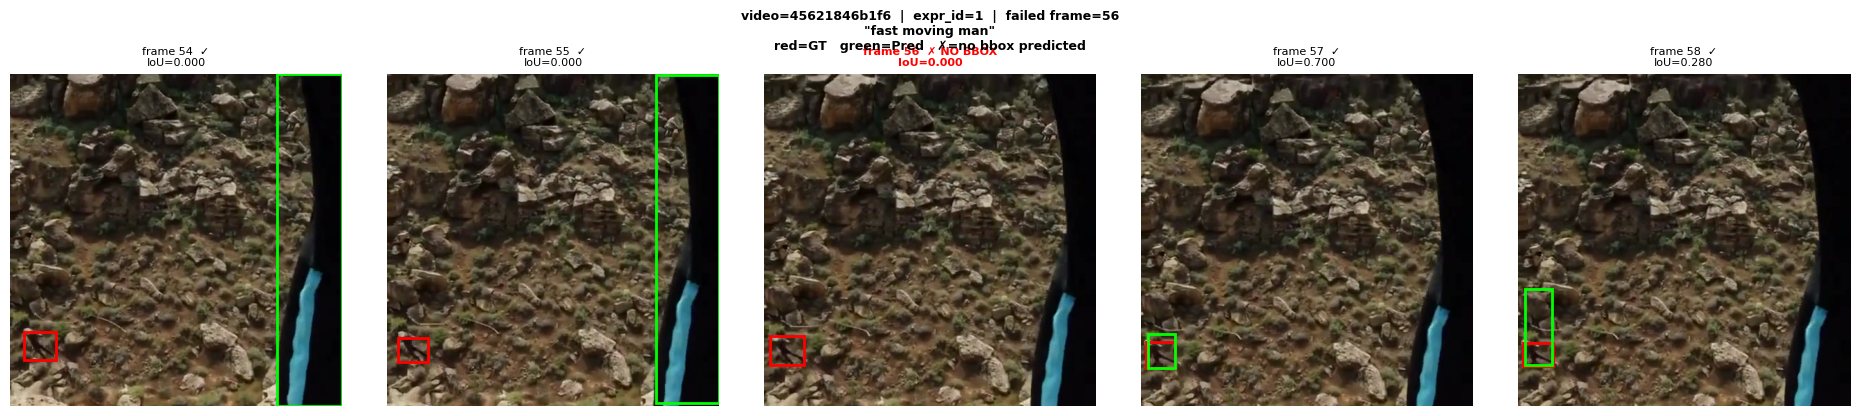

In [8]:
import json
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

MEVIS_DIR = Path("/home/jovyan/shares/SR006.nfs2/vashina/datasets/MeViS")
FM_DIR    = MEVIS_DIR / "data_sets/train/FirstMetricsData"
META_PATH = MEVIS_DIR / "data_sets/train/meta_expressions_v2.json"

with open(META_PATH, encoding="utf-8") as f:
    meta = json.load(f)

CSV_NAME = "humans_frequency_part0"
df_raw = pd.read_csv(RESULTS_DIR / f"{CSV_NAME}.csv")


def iou_single(row):
    gt_empty = (row.x_min_gt == 0 and row.x_max_gt == 0
                and row.y_min_gt == 0 and row.y_max_gt == 0)
    if gt_empty:
        return float("nan")
    if not row.success:
        return 0.0
    xi1 = max(row.x_min_gt, row.x_min_pred_px)
    yi1 = max(row.y_min_gt, row.y_min_pred_px)
    xi2 = min(row.x_max_gt, row.x_max_pred_px)
    yi2 = min(row.y_max_gt, row.y_max_pred_px)
    inter = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    gt_a   = (row.x_max_gt      - row.x_min_gt)      * (row.y_max_gt      - row.y_min_gt)
    pred_a = (row.x_max_pred_px - row.x_min_pred_px) * (row.y_max_pred_px - row.y_min_pred_px)
    union  = gt_a + pred_a - inter
    return inter / union if union > 0 else 0.0


WINDOW = 2  # кадров до и после

failed_rows = df_raw[df_raw["success"] == False]
print(f"Failed rows: {len(failed_rows)}")

for _, failed in failed_rows.iterrows():
    vid       = failed["video_name"]
    eid       = int(failed["expr_id"])
    fail_idx  = int(failed["n_frame"])
    cat       = failed["category"]
    prompt    = failed["prompt"]
    frames    = meta["videos"][vid]["frames"]

    window_indices = range(
        max(0, fail_idx - WINDOW),
        min(len(frames), fail_idx + WINDOW + 1),
    )
    n_cols = len(list(window_indices))

    fig, axes = plt.subplots(1, n_cols, figsize=(n_cols * 3.8, 4.2))
    if n_cols == 1:
        axes = [axes]

    for ax, frame_idx in zip(axes, window_indices):
        frame_name = frames[frame_idx]
        img_path   = FM_DIR / cat / vid / f"{frame_name}.jpg"

        try:
            img = Image.open(img_path).convert("RGB")
        except Exception as e:
            ax.set_title(f"f{frame_idx}\nNO IMAGE")
            ax.axis("off")
            continue

        ax.imshow(img)
        ax.axis("off")

        rows = df_raw[
            (df_raw["video_name"] == vid) &
            (df_raw["expr_id"]    == eid) &
            (df_raw["n_frame"]    == frame_idx)
        ]
        if rows.empty:
            ax.set_title(f"f{frame_idx}\nno data")
            continue

        row = rows.iloc[0]
        iou = iou_single(row)

        # GT — красный (всегда)
        gt_empty = (row.x_min_gt == 0 and row.x_max_gt == 0
                    and row.y_min_gt == 0 and row.y_max_gt == 0)
        if not gt_empty:
            ax.add_patch(patches.Rectangle(
                (row.x_min_gt, row.y_min_gt),
                row.x_max_gt - row.x_min_gt,
                row.y_max_gt - row.y_min_gt,
                linewidth=2, edgecolor="red", facecolor="none",
            ))

        # Pred — зелёный (только если success)
        if row.success:
            ax.add_patch(patches.Rectangle(
                (row.x_min_pred_px, row.y_min_pred_px),
                row.x_max_pred_px - row.x_min_pred_px,
                row.y_max_pred_px - row.y_min_pred_px,
                linewidth=2, edgecolor="lime", facecolor="none",
            ))

        is_fail = (frame_idx == fail_idx)
        iou_str = f"{iou:.3f}" if not np.isnan(iou) else "GT empty"
        status  = "✗ NO BBOX" if not row.success else "✓"
        color   = "red" if is_fail else "black"
        ax.set_title(
            f"frame {frame_idx}  {status}\nIoU={iou_str}",
            fontsize=8, color=color,
            fontweight="bold" if is_fail else "normal",
        )

    fig.suptitle(
        f'video={vid}  |  expr_id={eid}  |  failed frame={fail_idx}\n'
        f'"{prompt}"\n'
        f'red=GT   green=Pred   ✗=no bbox predicted',
        fontsize=9, fontweight="bold",
    )
    plt.tight_layout()
    plt.show()